# Applied Statistics Assessment: Iris Dataset

This notebook answers Problems 1–4 in the order set out in the Applied
Statistics assessment. Each problem begins with the **original question
wording** and is followed by numbered subsections (Problem 1.1, 1.2, etc.).
The code contains brief comments explaining the calculations, and the
results are interpreted after the relevant steps.

#### Import the libraries

In [1]:
# NumPy supports numerical arrays and straight-line fitting.
import numpy as np

# pandas loads the dataset and builds numerical summary tables.
import pandas as pd

# Matplotlib generates the histograms and scatter plots.
import matplotlib.pyplot as plt

# SciPy provides probability distributions and statistical hypothesis tests.
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")

#### Load the Iris dataset

In [10]:
# Prefer an optional repository copy for offline use; otherwise download CSV.
from pathlib import Path

DATA_URL = (
    "https://raw.githubusercontent.com/mwaskom/"
    "seaborn-data/master/iris.csv"
)
local_data = Path("data/iris.csv")
data_source = local_data if local_data.is_file() else DATA_URL

iris = pd.read_csv(data_source)
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Problem 1: Exploring Petal Length

### Problem 1.1 — Plot a histogram showing the petal lengths of all 150 flowers.

The histogram displays the observed frequencies across the complete dataset.

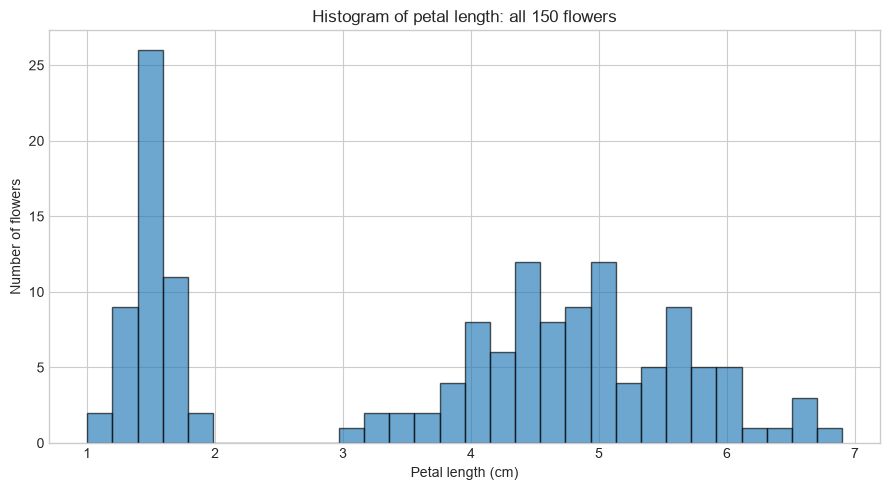

In [12]:
# Select the overall petal-length measurements for all 150 flowers.
overall_lengths = iris["petal_length"]
overall_mean = overall_lengths.mean()
overall_std = overall_lengths.std(ddof=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(overall_lengths, bins=30, edgecolor="black", alpha=0.65)
ax.set(xlabel="Petal length (cm)", ylabel="Number of flowers",
       title="Histogram of petal length: all 150 flowers")
plt.tight_layout()
plt.show()

### Problem 1.2 — On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

The histogram is redrawn on a density scale (`density=True`) so that it is
comparable with the normal probability density function. The red curve uses
the overall sample mean and standard deviation.


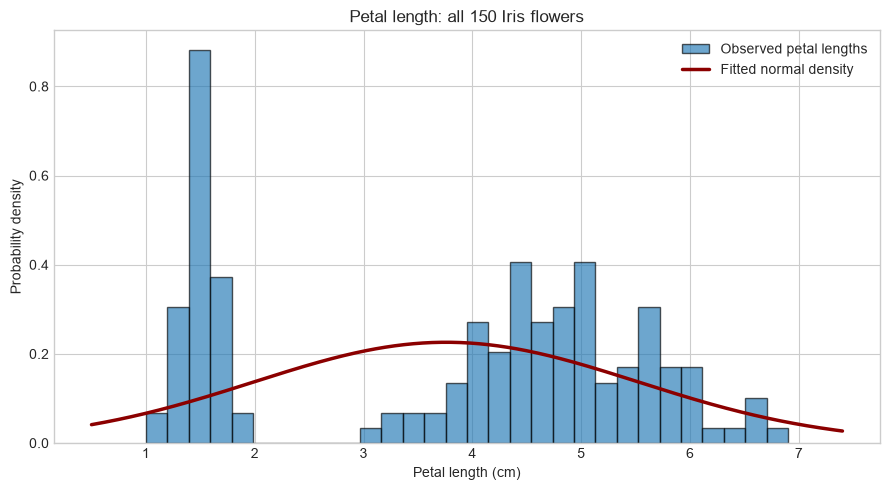

In [13]:
# Evaluate a normal PDF with the observed overall mean and standard deviation.
x_values = np.linspace(overall_lengths.min() - 0.5,
                       overall_lengths.max() + 0.5, 400)
normal_density = stats.norm.pdf(x_values, loc=overall_mean,
                                scale=overall_std)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(overall_lengths, bins=30, density=True, alpha=0.65,
        edgecolor="black", label="Observed petal lengths")
ax.plot(x_values, normal_density, color="darkred", linewidth=2.5,
        label="Fitted normal density")
ax.set(xlabel="Petal length (cm)", ylabel="Probability density",
       title="Petal length: all 150 Iris flowers")
ax.legend()
plt.tight_layout()
plt.show()

### Problem 1.3 — Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.

Each normal curve uses the mean and standard deviation of **that species**.


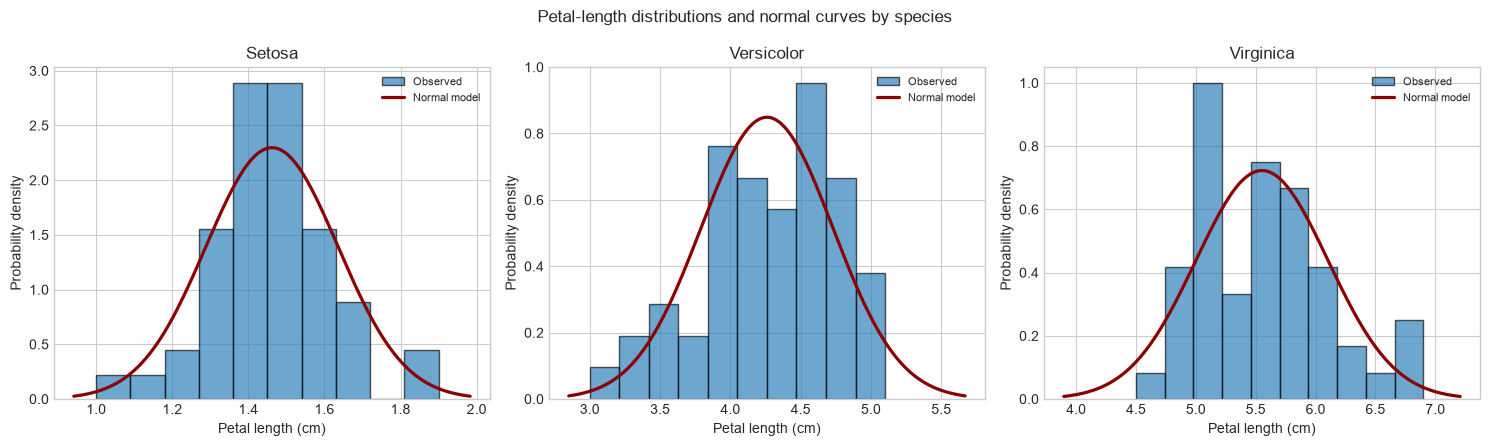

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, species in zip(axes, species_order):
    # Select this species and fit a normal density using its own parameters.
    lengths = iris.loc[iris["species"] == species, "petal_length"]
    group_mean = lengths.mean()
    group_std = lengths.std(ddof=1)
    group_x = np.linspace(group_mean - 3 * group_std,
                          group_mean + 3 * group_std, 300)

    ax.hist(lengths, bins=10, density=True, alpha=0.65,
            edgecolor="black", label="Observed")
    ax.plot(group_x, stats.norm.pdf(group_x, group_mean, group_std),
            color="darkred", linewidth=2.3, label="Normal model")
    ax.set(title=species.title(), xlabel="Petal length (cm)",
           ylabel="Probability density")
    ax.legend(fontsize=8)

fig.suptitle("Petal-length distributions and normal curves by species")
plt.tight_layout()
plt.show()


### Problem 1.4 — Report the mean and standard deviation of petal length for the complete dataset and for each species.

The sample standard deviation is calculated with `ddof=1` (dividing by
$n-1$). The following table also shows the sample sizes.


In [16]:
# Compute overall descriptive statistics for petal length.
overall_lengths = iris["petal_length"]
overall_mean = overall_lengths.mean()
overall_std = overall_lengths.std(ddof=1)

# Produce the same statistics separately for each species.
species_summary = (
    iris.groupby("species")["petal_length"]
    .agg(count="count", mean="mean", std="std")
    .reindex(species_order)
)

# Add the whole-dataset result to the top of the summary table.
all_flowers = pd.DataFrame(
    {"count": [len(iris)], "mean": [overall_mean], "std": [overall_std]},
    index=["all flowers"],
)
petal_summary = pd.concat([all_flowers, species_summary])
petal_summary.round(3)

,count,mean,std
all flowers,150,3.758,1.765
setosa,50,1.462,0.174
versicolor,50,4.260,0.470
virginica,50,5.552,0.552


### Problem 1.5 — Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

The overall distribution is **not adequately represented by one normal
curve**. Setosa forms a separate cluster of short petals, while the
versicolor and virginica values overlap. Pooling species with different
means produces a distribution that is not well modelled by a single normal
distribution.

The means (and sample standard deviations) are:

- **Setosa:** 1.462 cm (0.174 cm) — shortest petals and smallest spread.
- **Versicolor:** 4.260 cm (0.470 cm) — intermediate length and spread.
- **Virginica:** 5.552 cm (0.552 cm) — longest petals and largest spread.

Within each species, the fitted normal curve is a **more reasonable
approximation**, although none of the histograms is perfectly smooth. Each
species has just 50 observations, so the histograms provide visual evidence,
not definitive proof of normality.

## Problem 2: Correlation Between Petal Length and Petal Width


### Problem 2.1 — Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.

In [5]:
a + 1

NameError: name 'a' is not defined

## Problem 3: Title 3

Problem 3 involves

## Problem 4: Title 4

Problem 5 involves...

## End